# 03 · Exploratory Churn Analysis

**Purpose:** Find out which customer segments retain better or worse, using tenure-adjusted measures (Kaplan-Meier retention, log-rank tests, cohort heatmap), never raw "% churned".

**Input:** `data/processed/subscriptions_model.csv`, `reports/life_table_overall.csv`
**Output:** `reports/segment_retention.csv`, `reports/cohort_retention.csv`, 4 charts in `reports/figures/`

**Metrics used**
- **Retention after N days:** share of customers still subscribed N days after signup (Kaplan-Meier, with 95% confidence interval).
- **Log-rank test:** tests whether the retention curves of a segment's groups really differ.
- **Significance rule:** p-value below 0.05 divided by the number of variables tested (Bonferroni correction).

In [ ]:
#install lifelines %pip install lifelines
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

PROC = Path("../data/processed")
REPORTS = Path("../reports")
FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DATA_END = pd.Timestamp("2025-12-31")

subs = pd.read_csv(PROC / "subscriptions_model.csv", parse_dates=["signup_date", "churn_date", "end_date"])
monthly = subs[subs.plan_type == "monthly"]
print("all customers:", len(subs), "| monthly plans:", len(monthly))


all customers: 4200 | monthly plans: 2661


Plotting the overall monthly churn rate by tenure month.

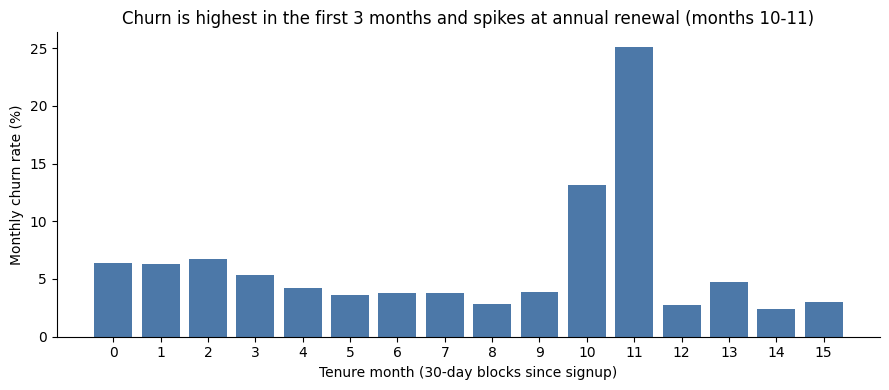

In [4]:
lt = pd.read_csv(REPORTS / "life_table_overall.csv")
lt = lt[lt.tenure_month <= 15]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lt.tenure_month, lt.churn_rate * 100, color="#4C78A8")
ax.set_xticks(lt.tenure_month)
ax.set_xlabel("Tenure month (30-day blocks since signup)")
ax.set_ylabel("Monthly churn rate (%)")
ax.set_title("Churn is highest in the first 3 months and spikes at annual renewal (months 10-11)")
fig.tight_layout()
fig.savefig(FIG / "01_churn_by_tenure_month.png", dpi=150)
plt.show()

Defining helper functions for Kaplan-Meier retention with a 95% confidence interval and for segment summary tables.


In [5]:
def km_estimate(g, day):
    """Share of customers still subscribed after `day` days, with a 95% confidence interval."""
    kmf = KaplanMeierFitter().fit(g.duration_days, g.event)
    surv = float(kmf.survival_function_at_times(day).iloc[0])
    lo, hi = kmf.confidence_interval_survival_function_.loc[:day].iloc[-1]
    return surv, float(lo), float(hi)

def segment_table(df, col, days=(90, 180)):
    rows = []
    for level, g in df.groupby(col):
        row = {col: level, "customers": len(g)}
        for d in days:
            s, lo, hi = km_estimate(g, d)
            row[f"ret_{d}d"] = round(s, 3)
            row[f"ci_{d}d"] = f"{lo:.2f}-{hi:.2f}"
        rows.append(row)
    return pd.DataFrame(row for row in rows)

def all_segments(df, cols, population):
    out = []
    for col in cols:
        t = segment_table(df, col).rename(columns={col: "level"})
        t.insert(0, "variable", col)
        out.append(t)
    res = pd.concat(out, ignore_index=True)
    res.insert(0, "population", population)
    return res

SEGMENT_COLS = ["plan_type", "plan_tier", "acquisition_channel", "primary_device", "age_group"]
MONTHLY_COLS = ["plan_tier", "acquisition_channel", "primary_device", "age_group"]   # plan_type is constant here

Comparing retention after 90 and 180 days across every segment, for all customers.


In [6]:
seg_all = all_segments(subs, SEGMENT_COLS, "all customers")
seg_all.drop(columns="population") 

,variable,level,customers,ret_90d,ci_90d,ret_180d,ci_180d
0,plan_type,annual,1539,0.976,0.97-0.98,0.950,0.94-0.96
1,plan_type,monthly,2661,0.727,0.71-0.74,0.580,0.56-0.60
2,plan_tier,basic,1976,0.821,0.80-0.84,0.713,0.69-0.73
3,plan_tier,plus,1501,0.820,0.80-0.84,0.723,0.70-0.75
4,plan_tier,premium,723,0.805,0.77-0.83,0.704,0.67-0.74
5,acquisition_channel,organic,1298,0.831,0.81-0.85,0.742,0.72-0.77
6,acquisition_channel,paid_social,989,0.858,0.83-0.88,0.732,0.70-0.76
7,acquisition_channel,partner,476,0.830,0.79-0.86,0.710,0.66-0.75
8,acquisition_channel,promo_offer,949,0.710,0.68-0.74,0.618,0.59-0.65
9,acquisition_channel,referral,488,0.899,0.87-0.92,0.798,0.76-0.83


Checking whether the share of annual plans differs across segments, since that could distort the comparisons.

In [7]:
mix = pd.concat({
    col: subs.groupby(col).plan_type.apply(lambda s: (s == "annual").mean()*100).round(1)
    for col in MONTHLY_COLS
})

mix.rename("pct_annual")

plan_tier            basic          37.2
                     plus           36.6
                     premium        35.0
acquisition_channel  organic        36.8
                     paid_social    35.2
                     partner        35.7
                     promo_offer    37.9
                     referral       37.5
primary_device       android        34.8
                     ios            38.1
                     web            36.5
age_group            18-24          35.8
                     25-34          37.1
                     35-44          37.3
                     45-54          37.2
                     55+            33.8
Name: pct_annual, dtype: float64

Repeating the comparison for monthly plans only, since annual customers are locked in until renewal and can hide differences.

In [8]:
seg_monthly = all_segments(monthly, MONTHLY_COLS, "monthly plans only")
seg_monthly.drop(columns="population")

,variable,level,customers,ret_90d,ci_90d,ret_180d,ci_180d
0,plan_tier,basic,1240,0.731,0.70-0.75,0.580,0.55-0.61
1,plan_tier,plus,951,0.730,0.70-0.76,0.589,0.56-0.62
2,plan_tier,premium,470,0.711,0.67-0.75,0.565,0.52-0.61
3,acquisition_channel,organic,820,0.746,0.72-0.77,0.616,0.58-0.65
4,acquisition_channel,paid_social,641,0.794,0.76-0.82,0.614,0.57-0.65
5,acquisition_channel,partner,306,0.752,0.70-0.80,0.600,0.54-0.66
6,acquisition_channel,promo_offer,589,0.553,0.51-0.59,0.423,0.38-0.46
7,acquisition_channel,referral,305,0.845,0.80-0.88,0.696,0.64-0.75
8,primary_device,android,1010,0.708,0.68-0.73,0.560,0.53-0.59
9,primary_device,ios,1223,0.720,0.69-0.74,0.589,0.56-0.62


Testing whether each segment's retention curves really differ (log-rank test, corrected for testing several variables).

In [9]:
rows = []
for name, df, cols in [("all customer", subs, SEGMENT_COLS), ("monthly plans only", monthly, MONTHLY_COLS)]:
    for col in cols:
        r = multivariate_logrank_test(df.duration_days, df[col], df.event)
        rows.append({
            "population": name,
            "variable": col,
            "chi_square": round(r.test_statistic, 1),
            "p_value": f"{r.p_value:.1e}",
            "significant": r.p_value < 0.05 / len(cols),    # Bonferroni: 0.05 divided by number of tests
        })

pd.DataFrame(rows)

,population,variable,chi_square,p_value,significant
0,all customer,plan_type,320.3,1.3e-71,True
1,all customer,plan_tier,0.7,7.1e-01,False
2,all customer,acquisition_channel,64.4,3.5e-13,True
3,all customer,primary_device,8.0,1.9e-02,False
4,all customer,age_group,1.5,8.2e-01,False
5,monthly plans only,plan_tier,1.0,6.0e-01,False
6,monthly plans only,acquisition_channel,81.8,7.3e-17,True
7,monthly plans only,primary_device,4.7,9.8e-02,False
8,monthly plans only,age_group,5.3,2.6e-01,False


Plotting Kaplan-Meier retention curves for monthly vs annual plans.


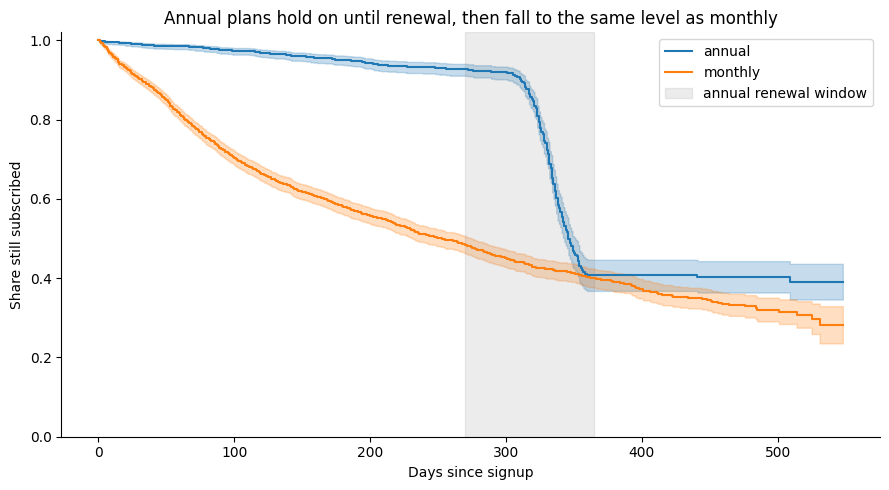

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for plan, g in subs.groupby("plan_type"):
    KaplanMeierFitter().fit(g.duration_days, g.event, label=plan).plot_survival_function(ax=ax)
ax.axvspan(270, 365, color="grey", alpha=0.15, label="annual renewal window")
ax.set_xlabel("Days since signup")
ax.set_ylabel("Share still subscribed")
ax.set_ylim(0, 1.02)
ax.set_title("Annual plans hold on until renewal, then fall to the same level as monthly")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "02_km_plan_type.png", dpi=150)
plt.show()

Plotting retention curves by acquisition channel, for monthly plans only.

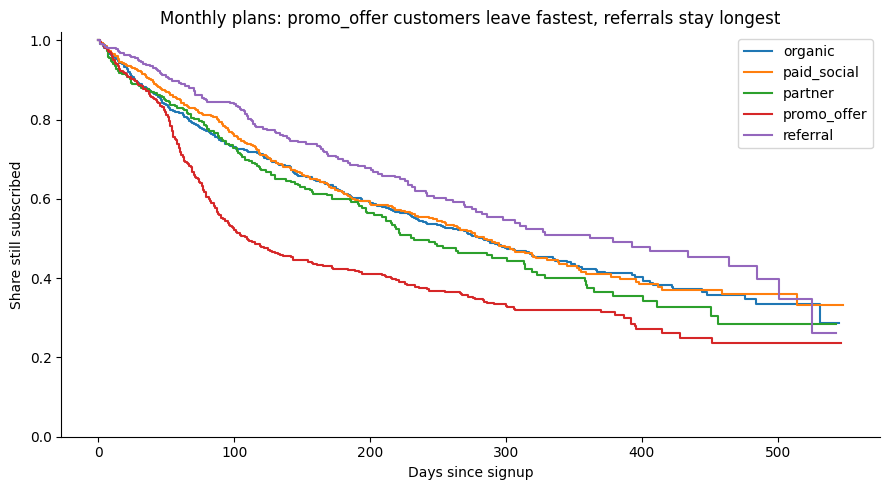

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for channel, g in monthly.groupby("acquisition_channel"):
    KaplanMeierFitter().fit(g.duration_days, g.event, label=channel).plot_survival_function(ax=ax, ci_show=False)
ax.set_xlabel("Days since signup")
ax.set_ylabel("Share still subscribed")
ax.set_ylim(0, 1.02)
ax.set_title("Monthly plans: promo_offer customers leave fastest, referrals stay longest")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "03_km_channel_monthly.png", dpi=150)
plt.show()

Building the cohort retention table: for each signup month, the % still subscribed at each tenure month, only where every customer in that cohort has been watched long enough.

In [12]:
subs["signup_month"] = subs.signup_date.dt.to_period("M")
months = range(1, 16)

rows = {}
for cohort, g in subs.groupby("signup_month"):
    observable_days = (DATA_END - g.signup_date.max()).days      # every customer in the cohort has been watched this long
    rows[str(cohort)] = {
        k: (g.duration_days >= 30 * k).mean() * 100 if observable_days >= 30 * k else np.nan
        for k in months
    }
retention = pd.DataFrame(rows).T
retention.columns.name = "tenure month"

print("cohorts:", len(retention), "| customers per cohort:", subs.groupby("signup_month").size().min(), "to", subs.groupby("signup_month").size().max())
retention[[1, 3, 6, 9, 12]].round(0)

cohorts: 16 | customers per cohort: 172 to 303


tenure month,1,3,6,9,12
2024-07,94.0,85.0,75.0,65.0,42.0
2024-08,91.0,81.0,72.0,61.0,41.0
2024-09,92.0,79.0,68.0,64.0,41.0
2024-10,94.0,84.0,69.0,64.0,36.0
2024-11,93.0,83.0,72.0,66.0,39.0
2024-12,95.0,83.0,71.0,65.0,40.0
2025-01,95.0,80.0,69.0,65.0,NaN
2025-02,94.0,81.0,74.0,68.0,NaN
2025-03,94.0,80.0,75.0,66.0,NaN
2025-04,95.0,86.0,77.0,NaN,NaN


Drawing the cohort retention heatmap.

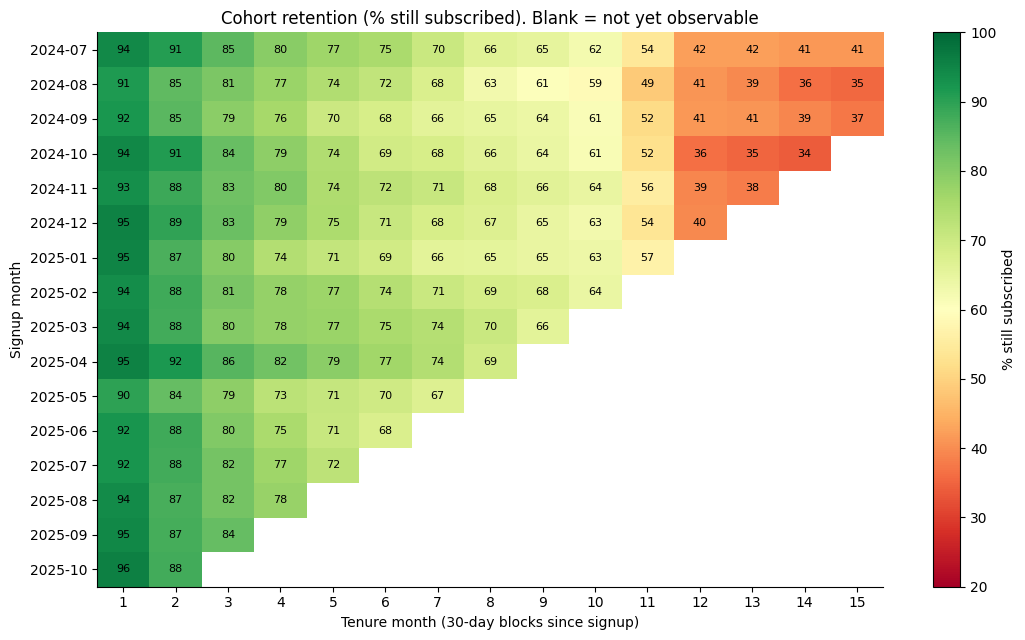

In [13]:
fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(np.ma.masked_invalid(retention.values), cmap="RdYlGn", vmin=20, vmax=100, aspect="auto")

ax.set_xticks(range(len(months)))
ax.set_xticklabels(list(months))
ax.set_yticks(range(len(retention)))
ax.set_yticklabels(retention.index)
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8)

ax.set_xlabel("Tenure month (30-day blocks since signup)")
ax.set_ylabel("Signup month")
ax.set_title("Cohort retention (% still subscribed). Blank = not yet observable")
fig.colorbar(im, label="% still subscribed")
fig.tight_layout()
fig.savefig(FIG / "04_cohort_retention_heatmap.png", dpi=150)
plt.show()

Saving the segment and cohort tables for the dashboard.

In [14]:
segments = pd.concat([seg_all, seg_monthly], ignore_index=True)
segments.to_csv(REPORTS / "segment_retention.csv", index=False)
retention.round(1).to_csv(REPORTS / "cohort_retention.csv")

print("saved:", len(segments), "segment rows;", len(retention), "cohorts")
print("figures:", sorted(p.name for p in FIG.glob("*.png")))

saved: 34 segment rows; 16 cohorts
figures: ['01_churn_by_tenure_month.png', '02_km_plan_type.png', '03_km_channel_monthly.png', '04_cohort_retention_heatmap.png']


**Results**

- **Plan type is the biggest difference.** Monthly customers keep 72.7% at 90 days, annual 97.6%. Both end up near 40% after the renewal drop at about day 330.
- **Acquisition channel is the biggest controllable difference.** Among monthly plans, promo_offer retains 55% at 90 days against 85% for referrals. Plan mix doesn't explain it (Cell 5), and the p-value is 7e-17.
- **Tier and age group show no real difference.** Don't build the story on them.
- **Device is a weak, unconfirmed signal.** Android is a little lower, but it doesn't survive the multiple-test correction. I'd keep it as a "watch" item.
- **Cohorts are stable**, so this isn't a problem that's getting worse or better over time.